# Étude progressive des réseaux de neurones sur le jeu de données HAR
## Version 2 : réseaux plus profonds

**Auteur :** Martine Ouedraogo (M2 MALIA, Deep Learning)

**Objectif de ce notebook.** Prolonger la Version 1 (une seule couche cachée) avec des réseaux de 2 à 4 couches cachées. Il reprend **exactement la même préparation des données** que la Version 1 (mêmes 540 variables, mêmes volontaires de validation 1, 3, 15, 25, 27, même standardisation apprise sur l'entraînement seulement), pour que les scores soient comparables.

**Règle :** le jeu de test n'est pas utilisé ici avant l'évaluation finale (5.2). Tous les choix se font sur la validation.

| Partie | Contenu | État |
|---|---|---|
| Préparation | Imports, données, découpage, DataLoaders, fonctions (repris de la V1) | fait |
| 3 | 3.2 Réseaux plus profonds et combinaisons d'activations | en cours |
| 4 | 4.1 Régularisation, 4.2 analyse et configurations retenues | en cours |
| 5 | 5.1 Courbes d'apprentissage ; 5.2 évaluation finale sur le test | 5.1 en cours |
| 6 | Visualisation t-SNE / UMAP | à faire |

## Préparation (identique à la Version 1)

> Je reprends ici sans changement le code de la V1 : imports, chargement, suppression des 21 colonnes copies, découpage par volontaire, standardisation, DataLoaders. Les explications et les justifications sont dans la V1 (Partie 1).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
np.random.seed(SEED)

In [2]:
train = pd.read_csv("HAR/train.csv")
test = pd.read_csv("HAR/test.csv")

# Variables : on enlève subject et Activity, puis les 21 colonnes copies exactes
X_train = train.drop(columns=["subject", "Activity"])
colonnes_copies = set(X_train.columns[X_train.T.duplicated().to_numpy()])
feature_cols = [c for c in X_train.columns if c not in colonnes_copies]
print("Variables conservées :", len(feature_cols))

encoder = LabelEncoder()
encoder.fit(train["Activity"])

# Découpage par volontaire : mêmes 5 volontaires de validation que la V1
volontaires = sorted(train["subject"].unique().tolist())
vol_val = sorted(np.random.RandomState(SEED).choice(volontaires, size=5, replace=False).tolist())
assert vol_val == [1, 3, 15, 25, 27]
masque_val = train["subject"].isin(vol_val)
tr_df, val_df = train[~masque_val], train[masque_val]

X_tr, X_val = tr_df[feature_cols].to_numpy(), val_df[feature_cols].to_numpy()
y_tr, y_val = encoder.transform(tr_df["Activity"]), encoder.transform(val_df["Activity"])

# Standardisation apprise sur l'entraînement seulement
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_val_s = scaler.transform(X_tr), scaler.transform(X_val)
print("Entraînement :", X_tr_s.shape, "| validation :", X_val_s.shape)

Variables conservées : 540
Entraînement : (5551, 540) | validation : (1801, 540)


In [3]:
X_tr_t = torch.tensor(X_tr_s, dtype=torch.float32)
X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
y_tr_t = torch.tensor(y_tr, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)

BATCH_SIZE = 64
N_ENTREES, N_CLASSES = X_tr_t.shape[1], 6
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=512, shuffle=False)
train_eval_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=512, shuffle=False)
lossfn = nn.CrossEntropyLoss()
N_EPOCHS = 30
SEEDS = [0, 1, 2, 3, 4]


def train_epoch(model, loader, optimizer, lossfn):
    model.train()
    total_loss = 0.0
    for X, y in loader:
        optimizer.zero_grad()
        perte = lossfn(model(X), y)
        perte.backward()
        optimizer.step()
        total_loss += perte.item() * len(y)
    return total_loss / len(loader.dataset)


def evaluate(model, loader, lossfn):
    model.eval()
    total_loss, y_vrai, y_pred = 0.0, [], []
    with torch.no_grad():
        for X, y in loader:
            sortie = model(X)
            total_loss += lossfn(sortie, y).item() * len(y)
            y_pred.append(sortie.argmax(dim=1))
            y_vrai.append(y)
    y_vrai, y_pred = torch.cat(y_vrai).numpy(), torch.cat(y_pred).numpy()
    return (total_loss / len(loader.dataset), accuracy_score(y_vrai, y_pred),
            f1_score(y_vrai, y_pred, average="macro"))


def moy_std(serie, nd=4):
    return f"{serie.mean():.{nd}f} ± {serie.std():.{nd}f}"

# Partie 3 : Extension de l'architecture (suite)

> **Ce qui est demandé dans cette partie :** la 3.1 (taille de la couche cachée) est dans la Version 1. Ici, la 3.2.

## 3.2 Réseaux plus profonds

> **Demandé :** implémenter des réseaux plus profonds (2 à 4 couches cachées). Tester différentes combinaisons de fonctions d'activation dans les couches intermédiaires et comparer les résultats (accuracy, F1-score), en tenant compte du nombre de paramètres et du temps d'entraînement.

Mes étapes : 3.2.1 (réseau à nombre de couches variable), 3.2.2 (configurations testées), 3.2.3 (entraînement avec 5 graines), 3.2.4 (résultats), 3.2.5 (conclusion).

### 3.2.1 Un réseau à nombre de couches variable

Je généralise le réseau de la V1 : on donne la liste des activations, une par couche cachée, et la largeur commune des couches. La longueur de la liste fixe la profondeur. Je prends 128 neurones par couche, la taille retenue en 3.1, et Adam avec le pas 3e-4 de 2.3, pour ne changer que la profondeur et les activations.

In [4]:
class MLPProfond(nn.Module):
    # Entrées -> [Linear -> activation] x profondeur -> Linear (6 scores bruts)
    def __init__(self, n_entrees, largeur, n_classes, activations):
        super().__init__()
        couches, n_in = [], n_entrees
        for act in activations:
            couches += [nn.Linear(n_in, largeur), act()]
            n_in = largeur
        couches.append(nn.Linear(n_in, n_classes))
        self.reseau = nn.Sequential(*couches)

    def forward(self, x):
        return self.reseau(x)


print(MLPProfond(N_ENTREES, 128, N_CLASSES, [nn.ReLU, nn.Tanh, nn.ReLU]))

MLPProfond(
  (reseau): Sequential(
    (0): Linear(in_features=540, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Tanh()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=6, bias=True)
  )
)


### 3.2.2 Configurations testées

Je teste 2, 3 et 4 couches cachées. Pour chaque profondeur je prends les trois activations identiques partout (ReLU, Tanh, Sigmoid), puis quelques mélanges. Le but des mélanges est de voir si une activation différente selon la couche change quelque chose. Je rappelle que le nombre de paramètres dépend seulement de la profondeur, pas de l'activation.

In [5]:
R, T, S = nn.ReLU, nn.Tanh, nn.Sigmoid
CONFIGS = {
    # 1 couche (référence de la V1, 128 neurones)
    "1 : ReLU": [R],
    # 2 couches
    "2 : ReLU-ReLU": [R, R], "2 : Tanh-Tanh": [T, T], "2 : Sigmoid-Sigmoid": [S, S],
    "2 : ReLU-Tanh": [R, T], "2 : Tanh-ReLU": [T, R],
    # 3 couches
    "3 : ReLU-ReLU-ReLU": [R, R, R], "3 : Tanh-Tanh-Tanh": [T, T, T], "3 : Sigmoid-Sigmoid-Sigmoid": [S, S, S],
    "3 : ReLU-ReLU-Tanh": [R, R, T], "3 : Tanh-ReLU-ReLU": [T, R, R], "3 : ReLU-Tanh-ReLU": [R, T, R],
    # 4 couches
    "4 : ReLU x4": [R] * 4, "4 : Tanh x4": [T] * 4, "4 : Sigmoid x4": [S] * 4,
    "4 : ReLU-ReLU-Tanh-Tanh": [R, R, T, T],
}
for nom, acts in CONFIGS.items():
    n = sum(p.numel() for p in MLPProfond(N_ENTREES, 128, N_CLASSES, acts).parameters())
    print(f"{nom:30s} {n:7d} paramètres")

1 : ReLU                         70022 paramètres
2 : ReLU-ReLU                    86534 paramètres
2 : Tanh-Tanh                    86534 paramètres
2 : Sigmoid-Sigmoid              86534 paramètres
2 : ReLU-Tanh                    86534 paramètres
2 : Tanh-ReLU                    86534 paramètres
3 : ReLU-ReLU-ReLU              103046 paramètres
3 : Tanh-Tanh-Tanh              103046 paramètres
3 : Sigmoid-Sigmoid-Sigmoid     103046 paramètres
3 : ReLU-ReLU-Tanh              103046 paramètres
3 : Tanh-ReLU-ReLU              103046 paramètres
3 : ReLU-Tanh-ReLU              103046 paramètres
4 : ReLU x4                     119558 paramètres
4 : Tanh x4                     119558 paramètres
4 : Sigmoid x4                  119558 paramètres
4 : ReLU-ReLU-Tanh-Tanh         119558 paramètres


### 3.2.3 Entraînement avec 5 graines

J'entraîne chaque configuration 30 époques avec les 5 graines (0 à 4), comme en 2.3, et je mesure le temps de chaque entraînement (évaluations à chaque époque comprises). Les temps sont mesurés sur mon ordinateur, ils servent à comparer les configurations entre elles.

In [6]:
def fit_profond(activations, lr=3e-4, n_epochs=N_EPOCHS, largeur=128, seed=SEED):
    torch.manual_seed(seed)
    model = MLPProfond(N_ENTREES, largeur, N_CLASSES, activations)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}
    for _ in range(n_epochs):
        train_epoch(model, loader, opt, lossfn)
        tl, ta, _ = evaluate(model, train_eval_loader, lossfn)
        vl, va, vf = evaluate(model, val_loader, lossfn)
        for cle, val in zip(hist, (tl, ta, vl, va, vf)):
            hist[cle].append(val)
    return model, hist


lignes, hist_profond = [], {}
for nom, acts in CONFIGS.items():
    n_params = sum(p.numel() for p in MLPProfond(N_ENTREES, 128, N_CLASSES, acts).parameters())
    for graine in SEEDS:
        t0 = time.time()
        _, h = fit_profond(acts, seed=graine)
        duree = time.time() - t0
        hist_profond[(nom, graine)] = h
        lignes.append({"config": nom, "profondeur": len(acts), "paramètres": n_params, "graine": graine,
                       "acc_train": h["train_acc"][-1], "acc_val": h["val_acc"][-1],
                       "f1_val": h["val_f1"][-1], "perte_train": h["train_loss"][-1],
                       "perte_val": h["val_loss"][-1], "temps_s": duree})
profond_df = pd.DataFrame(lignes)
print("Nombre d'entraînements :", len(profond_df))

Nombre d'entraînements : 80


### 3.2.4 Résultats

In [7]:
resume = []
for nom, d in profond_df.groupby("config", sort=False):
    resume.append({"configuration": nom, "paramètres": d["paramètres"].iloc[0],
                   "acc. entraînement": moy_std(d["acc_train"]),
                   "acc. validation": moy_std(d["acc_val"]),
                   "F1 macro validation": moy_std(d["f1_val"]),
                   "temps (s)": f"{d['temps_s'].mean():.1f}"})
tab_profond = pd.DataFrame(resume).set_index("configuration")
tab_profond

,paramètres,acc. entraînement,acc. validation,F1 macro validation,temps (s)
configuration,,,,,
1 : ReLU,70022,0.9955 ± 0.0010,0.9592 ± 0.0030,0.9561 ± 0.0032,1.4
2 : ReLU-ReLU,86534,0.9969 ± 0.0029,0.9578 ± 0.0058,0.9542 ± 0.0065,1.5
2 : Tanh-Tanh,86534,0.9984 ± 0.0019,0.9564 ± 0.0049,0.9520 ± 0.0056,1.6
2 : Sigmoid-Sigmoid,86534,0.9892 ± 0.0009,0.9606 ± 0.0044,0.9572 ± 0.0051,1.5
2 : ReLU-Tanh,86534,0.9986 ± 0.0025,0.9610 ± 0.0051,0.9576 ± 0.0057,1.6
2 : Tanh-ReLU,86534,0.9985 ± 0.0018,0.9550 ± 0.0030,0.9508 ± 0.0034,1.5
3 : ReLU-ReLU-ReLU,103046,0.9948 ± 0.0037,0.9545 ± 0.0041,0.9507 ± 0.0046,1.7
3 : Tanh-Tanh-Tanh,103046,0.9987 ± 0.0013,0.9532 ± 0.0072,0.9487 ± 0.0080,1.9
3 : Sigmoid-Sigmoid-Sigmoid,103046,0.9905 ± 0.0016,0.9479 ± 0.0127,0.9434 ± 0.0143,1.8


Je remarque que le nombre de paramètres ne dépend que de la profondeur (86 534 pour 2 couches, 103 046 pour 3, 119 558 pour 4), pas de l'activation. À paramètres égaux, les performances varient autant à l'intérieur d'une profondeur qu'entre profondeurs : ce n'est donc pas le nombre de paramètres qui explique les différences.

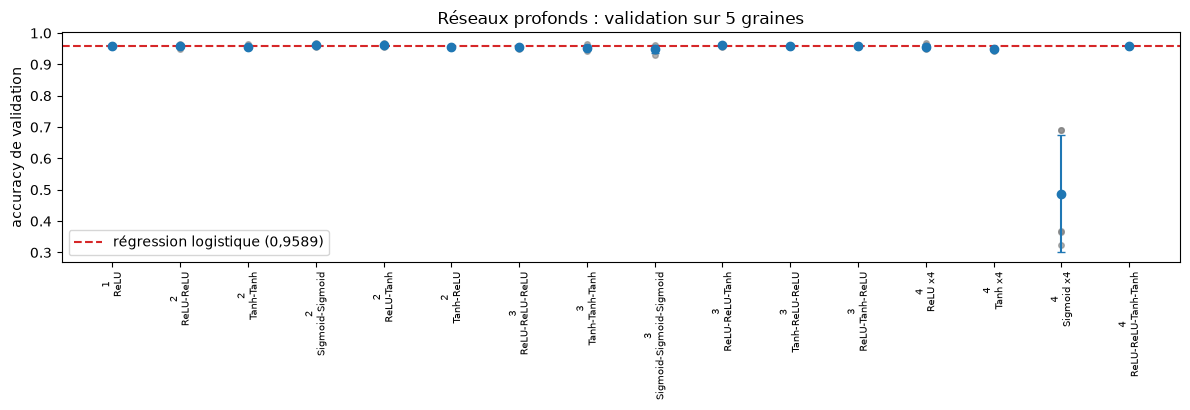

In [8]:
# Accuracy de validation par configuration (points = graines, point bleu = moyenne ± écart-type)
fig, ax = plt.subplots(figsize=(12, 4.2))
noms = list(CONFIGS)
for k, nom in enumerate(noms):
    d = profond_df[profond_df["config"] == nom]
    ax.scatter([k] * len(d), d["acc_val"], color="gray", alpha=0.6, s=16)
    ax.errorbar(k, d["acc_val"].mean(), yerr=d["acc_val"].std(), fmt="o", color="C0", capsize=3)
ax.axhline(0.9589, color="C3", linestyle="--", label="régression logistique (0,9589)")
ax.set_xticks(range(len(noms)))
ax.set_xticklabels([n.replace(" : ", "\n") for n in noms], fontsize=7, rotation=90)
ax.set_ylabel("accuracy de validation")
ax.set_title("Réseaux profonds : validation sur 5 graines")
ax.legend()
plt.tight_layout()
plt.show()

Je constate que presque tous les réseaux sont entre 0,95 et 0,961 de validation, dans les barres d'erreur les uns des autres. Les 3 Sigmoid profonds ressortent : celui à 3 couches a un écart-type de 1,3 point (instable) et celui à 4 couches est loin sous la ligne rouge (0,49). Les réseaux Tanh à 4 couches (0,9484) sont aussi un peu plus bas. À l'entraînement, les réseaux avec Tanh ou un mélange ReLU-Tanh atteignent 99,8 à 99,98 %, plus que ReLU seul : ils surapprennent davantage sans gagner en validation.

In [9]:
# Par profondeur : meilleure moyenne, paramètres, temps, et écart train - validation
par_prof = profond_df.assign(ecart=(profond_df["acc_train"] - profond_df["acc_val"]) * 100)
print(par_prof.groupby("profondeur").agg(paramètres=("paramètres", "first"),
      acc_val=("acc_val", "mean"), f1_val=("f1_val", "mean"),
      ecart_train_val_pts=("ecart", "mean"), temps_s=("temps_s", "mean")).round(4).to_string())

# Règle de 2.3 : une différence est nette si elle dépasse 2 x le plus grand écart-type
def acc_cfg(nom):
    return profond_df[profond_df["config"] == nom]["acc_val"]

def comparer(a, b):
    sa, sb = acc_cfg(a), acc_cfg(b)
    diff, seuil = sa.mean() - sb.mean(), 2 * max(sa.std(), sb.std())
    print(f"{a:28s} contre {b:28s}: {diff * 100:+.2f} pts | seuil {seuil * 100:.2f} | nette ? {'oui' if abs(diff) > seuil else 'non'}")

moyennes = profond_df.groupby("config")["acc_val"].mean()
meilleure = moyennes.idxmax()
print("\nMeilleure moyenne :", meilleure, round(moyennes.max(), 4))
for a, b in [("2 : ReLU-ReLU", "1 : ReLU"), ("3 : ReLU-ReLU-ReLU", "1 : ReLU"), ("4 : ReLU x4", "1 : ReLU"),
             ("3 : ReLU-ReLU-ReLU", "2 : ReLU-ReLU"), ("4 : ReLU x4", "3 : ReLU-ReLU-ReLU"),
             ("3 : ReLU-ReLU-ReLU", "3 : Sigmoid-Sigmoid-Sigmoid"), ("4 : ReLU x4", "4 : Sigmoid x4"),
             ("3 : ReLU-ReLU-ReLU", "3 : Tanh-Tanh-Tanh"), (meilleure, "1 : ReLU")]:
    comparer(a, b)

            paramètres  acc_val  f1_val  ecart_train_val_pts  temps_s
profondeur                                                           
1                70022   0.9592  0.9561               3.6215   1.4259
2                86534   0.9582  0.9544               3.8161   1.5558
3               103046   0.9554  0.9515               4.1814   1.7578
4               119558   0.8376  0.7959               3.0189   2.0262

Meilleure moyenne : 2 : ReLU-Tanh 0.961
2 : ReLU-ReLU                contre 1 : ReLU                    : -0.14 pts | seuil 1.16 | nette ? non
3 : ReLU-ReLU-ReLU           contre 1 : ReLU                    : -0.48 pts | seuil 0.82 | nette ? non
4 : ReLU x4                  contre 1 : ReLU                    : -0.22 pts | seuil 1.40 | nette ? non
3 : ReLU-ReLU-ReLU           contre 2 : ReLU-ReLU               : -0.33 pts | seuil 1.16 | nette ? non
4 : ReLU x4                  contre 3 : ReLU-ReLU-ReLU          : +0.26 pts | seuil 1.40 | nette ? non
3 : ReLU-ReLU-ReLU      

Je remarque que les écarts avec le réseau à une couche sont tous petits et que le seul écart « net » concerne Sigmoid à 4 couches. Pour les profondeurs, la moyenne de la ligne 4 est tirée vers le bas (0,8376) uniquement par ce Sigmoid effondré. Je ne retiens donc pas cette ligne comme représentative de la profondeur 4 : les autres réseaux à 4 couches sont à 0,948 à 0,957. Le temps augmente avec la profondeur (1,4 s, 1,6 s, 1,9 s, 2,8 s).

Le réseau Sigmoid à 4 couches s'effondre avec le pas 3e-4 : il n'apprend même pas le train. Je soupçonne un problème de pas trop petit pour des gradients qui s'affaiblissent à travers les sigmoïdes (cours : gradients qui disparaissent). Je vérifie en refaisant les Sigmoid avec le pas 3e-3, celui qui avait été retenu pour Sigmoid + Adam en 2.2, pour les 3 profondeurs.

In [10]:
lignes = []
for acts, nom in [([S] * 2, "2 : Sigmoid-Sigmoid"), ([S] * 3, "3 : Sigmoid x3"), ([S] * 4, "4 : Sigmoid x4")]:
    for graine in SEEDS:
        _, h = fit_profond(acts, lr=3e-3, seed=graine)
        lignes.append({"config": nom, "graine": graine, "acc_train": h["train_acc"][-1],
                       "acc_val": h["val_acc"][-1], "f1_val": h["val_f1"][-1]})
sig_df = pd.DataFrame(lignes)
for nom, d in sig_df.groupby("config"):
    print(f"{nom:22s} pas 3e-3 | train {moy_std(d['acc_train'])} | val {moy_std(d['acc_val'])} | F1 {moy_std(d['f1_val'])}")
print("\nSigmoid x4, pas 3e-4, accuracy de validation par graine :",
      [round(v, 3) for v in profond_df[profond_df["config"] == "4 : Sigmoid x4"]["acc_val"]])

2 : Sigmoid-Sigmoid    pas 3e-3 | train 1.0000 ± 0.0000 | val 0.9637 ± 0.0058 | F1 0.9608 ± 0.0068
3 : Sigmoid x3         pas 3e-3 | train 0.9940 ± 0.0067 | val 0.9407 ± 0.0058 | F1 0.9353 ± 0.0064
4 : Sigmoid x4         pas 3e-3 | train 0.5998 ± 0.2728 | val 0.5759 ± 0.2420 | F1 0.4723 ± 0.3137

Sigmoid x4, pas 3e-4, accuracy de validation par graine : [0.368, 0.69, 0.324, 0.691, 0.366]


Je constate que Sigmoid à 2 couches avec le pas 3e-3 donne 0,9637 en validation (train à 100 %), la meilleure valeur de ce notebook, mais cela vient d'un pas choisi en plus, donc je ne la compare pas aux autres. Avec 3 couches Sigmoid baisse à 0,9407, puis à 4 couches le réseau n'apprend plus (0,60 en train, très variable selon la graine : écart-type 0,27). Le pas plus grand n'a donc pas sauvé Sigmoid à 4 couches.

### 3.2.5 Conclusion de 3.2

- **Aller plus profond n'aide pas ici.** La meilleure moyenne par profondeur (toutes configurations confondues) est de 0,9592 avec 1 couche, 0,9582 avec 2 et 0,9554 avec 3. Aucune différence avec le réseau à une couche n'est nette selon la règle de 2.3 (écarts de -0,5 à +0,2 point pour des seuils de 0,8 à 1,4 point). Les 70 000 à 120 000 paramètres de plus et le temps d'entraînement doublé (1,4 s contre 2,8 s) ne rapportent rien.
- **Le surapprentissage augmente avec la profondeur** : l'écart train - validation passe de 3,6 à 4,2 points entre 1 et 3 couches. Plusieurs réseaux atteignent 99,9 % en entraînement (ReLU-ReLU-Tanh : 0,9998). C'est un argument pour la régularisation de la Partie 4.
- **Les combinaisons d'activations ne se distinguent pas.** ReLU-Tanh à 2 couches a la meilleure moyenne (0,9610) mais l'écart avec ReLU seul à 1 couche est de +0,18 point, bien sous le seuil. Je ne retiens aucune combinaison comme meilleure.
- **Le seul résultat net est un échec.** Sigmoid à 4 couches n'apprend pas correctement (accuracy d'entraînement 0,48 en moyenne ; en validation, de 0,32 à 0,69 selon la graine). Avec ReLU, 4 couches fonctionnent (0,9570). Le pas plus grand (3e-3) ne répare pas le problème (0,60), donc ce n'est pas seulement un pas mal choisi. L'explication la plus probable est celle du cours, les gradients qui s'affaiblissent à chaque sigmoïde, mais je ne l'ai pas vérifiée directement.

Pour la suite j'avance avec un réseau à **3 couches cachées ReLU** (le cas cité par l'énoncé), même si la V1 à une couche fait aussi bien : c'est le réseau profond sur lequel je testerai la régularisation en Partie 4, pour voir si elle réduit le surapprentissage. Je garde en tête que la V1 reste une référence très compétitive.

# Partie 4 : Régularisation et robustesse

> **Ce qui est demandé dans cette partie :**
> **4.1** Si on observe du surapprentissage, tester des techniques de régularisation : Dropout (p = 0,1 / 0,3 / 0,5), Weight Decay (régularisation L2), Batch Normalization, Early stopping (arrêt si le score de validation ne s'améliore plus).
> **4.2** Analyser l'effet de chaque méthode sur la stabilité et la généralisation. Garder en mémoire les 2 ou 3 configurations les plus performantes sur la validation pour la suite.

Je constate du surapprentissage depuis la Partie 3 (le réseau à 3 couches ReLU atteint ~99,5 % en entraînement pour ~95,5 % en validation), donc je teste les quatre techniques. Mes étapes : 4.1.1 (outils), 4.1.2 (configurations), 4.1.3 (entraînement avec 5 graines), 4.2.1 (effet sur la généralisation), 4.2.2 (stabilité), 4.2.3 (configurations retenues).

## 4.1 Techniques de régularisation

### 4.1.1 Les outils

Je pars du réseau de référence de la 3.2 : 3 couches cachées de 128 neurones en ReLU, Adam au pas 3e-4, 30 époques. Je garde tout cela fixe et je n'ajoute qu'une technique à la fois :

- **Dropout** : pendant l'entraînement, chaque neurone de sortie d'une couche cachée est éteint au hasard avec une probabilité p. Le réseau ne peut plus compter sur un neurone précis.
- **Weight decay (L2)** : on pénalise les poids trop grands. Avec Adam, je le règle par le paramètre `weight_decay` de l'optimiseur.
- **Batch Normalization** : on normalise les sorties de chaque couche cachée (avant ReLU) sur le mini-batch. Elle stabilise l'apprentissage et a aussi un petit effet régularisant.
- **Early stopping** : je suis le F1 macro de validation à chaque époque, j'arrête si il ne s'améliore plus pendant 8 époques, et je reprends les poids de la meilleure époque (maximum 100 époques).

Attention à une limite : l'early stopping choisit l'époque avec la validation. Son score de validation est donc un peu optimiste par rapport aux autres techniques. Je le garde en tête dans l'analyse.

In [11]:
class MLPReg(nn.Module):
    # n_couches x [Linear -> (BatchNorm) -> activation -> (Dropout)] puis Linear de sortie
    def __init__(self, n_entrees, largeur, n_classes, n_couches=3, activation=nn.ReLU, dropout=0.0, bn=False):
        super().__init__()
        couches, n_in = [], n_entrees
        for _ in range(n_couches):
            couches.append(nn.Linear(n_in, largeur))
            if bn:
                couches.append(nn.BatchNorm1d(largeur))
            couches.append(activation())
            if dropout > 0:
                couches.append(nn.Dropout(dropout))
            n_in = largeur
        couches.append(nn.Linear(n_in, n_classes))
        self.reseau = nn.Sequential(*couches)

    def forward(self, x):
        return self.reseau(x)


def fit_reg(dropout=0.0, wd=0.0, bn=False, early=False, lr=3e-4, seed=SEED, largeur=128, n_couches=3):
    # Early stopping : max 100 époques, patience 8 sur le F1 macro de validation, poids de la meilleure époque
    torch.manual_seed(seed)
    model = MLPReg(N_ENTREES, largeur, N_CLASSES, n_couches, nn.ReLU, dropout, bn)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}
    max_ep, patience = (100, 8) if early else (N_EPOCHS, None)
    meilleur, ep_best, etat_best = -1.0, 0, None
    for ep in range(max_ep):
        train_epoch(model, loader, opt, lossfn)
        tl, ta, _ = evaluate(model, train_eval_loader, lossfn)
        vl, va, vf = evaluate(model, val_loader, lossfn)
        for cle, val in zip(hist, (tl, ta, vl, va, vf)):
            hist[cle].append(val)
        if early:
            if vf > meilleur:
                meilleur, ep_best = vf, ep
                etat_best = {k: v.clone() for k, v in model.state_dict().items()}
            elif ep - ep_best >= patience:
                break
    if early:
        model.load_state_dict(etat_best)
    hist["ep_retenue"] = ep_best if early else len(hist["val_acc"]) - 1
    return model, hist

### 4.1.2 Configurations testées

Je teste chaque technique seule (dropout à 0,1 / 0,3 / 0,5 ; weight decay à 1e-5, 1e-4, 1e-3, 1e-2 ; Batch Normalization ; early stopping), puis 4 combinaisons que j'ai choisies avant de voir les résultats : dropout 0,3 + weight decay 1e-4, Batch Normalization + dropout 0,3, Batch Normalization + weight decay 1e-4, dropout 0,3 + early stopping.

In [12]:
CONFIGS_REG = {
    "référence (aucune)": dict(),
    "dropout 0,1": dict(dropout=0.1), "dropout 0,3": dict(dropout=0.3), "dropout 0,5": dict(dropout=0.5),
    "weight decay 1e-5": dict(wd=1e-5), "weight decay 1e-4": dict(wd=1e-4),
    "weight decay 1e-3": dict(wd=1e-3), "weight decay 1e-2": dict(wd=1e-2),
    "batch norm": dict(bn=True),
    "early stopping": dict(early=True),
    "dropout 0,3 + wd 1e-4": dict(dropout=0.3, wd=1e-4),
    "batch norm + dropout 0,3": dict(bn=True, dropout=0.3),
    "batch norm + wd 1e-4": dict(bn=True, wd=1e-4),
    "dropout 0,3 + early stopping": dict(dropout=0.3, early=True),
}
print(len(CONFIGS_REG), "configurations x", len(SEEDS), "graines =", len(CONFIGS_REG) * len(SEEDS), "entraînements")

14 configurations x 5 graines = 70 entraînements


### 4.1.3 Entraînement avec 5 graines

Même méthode qu'en 2.3 et 3.2 : 5 graines (0 à 4) par configuration, moyenne ± écart-type, temps mesuré. Pour les configurations sans early stopping, je prends le score de la dernière époque (30). Pour l'early stopping, c'est celui de l'époque retenue.

In [13]:
lignes, hist_reg = [], {}
for nom, params in CONFIGS_REG.items():
    for graine in SEEDS:
        t0 = time.time()
        _, h = fit_reg(seed=graine, **params)
        duree = time.time() - t0
        i = h["ep_retenue"]
        hist_reg[(nom, graine)] = h
        lignes.append({"config": nom, "graine": graine, "epoque": i + 1,
                       "acc_train": h["train_acc"][i], "acc_val": h["val_acc"][i], "f1_val": h["val_f1"][i],
                       "perte_train": h["train_loss"][i], "perte_val": h["val_loss"][i],
                       # stabilité : fluctuation de l'accuracy de validation d'une époque à l'autre (10 dernières)
                       "fluct_val": float(np.std(h["val_acc"][max(0, i - 9):i + 1])),
                       "temps_s": duree})
reg_df = pd.DataFrame(lignes)
print("Nombre d'entraînements :", len(reg_df))

Nombre d'entraînements : 70


## 4.2 Analyse de l'effet de chaque méthode

### 4.2.1 Effet sur la généralisation

In [14]:
resume = []
for nom, d in reg_df.groupby("config", sort=False):
    resume.append({"configuration": nom,
                   "acc. entraînement": moy_std(d["acc_train"]),
                   "acc. validation": moy_std(d["acc_val"]),
                   "F1 macro validation": moy_std(d["f1_val"]),
                   "écart train - val (pts)": f"{(d['acc_train'] - d['acc_val']).mean() * 100:.2f}",
                   "époques": f"{d['epoque'].mean():.0f}",
                   "temps (s)": f"{d['temps_s'].mean():.1f}"})
tab_reg = pd.DataFrame(resume).set_index("configuration")
tab_reg

,acc. entraînement,acc. validation,F1 macro validation,écart train - val (pts),époques,temps (s)
configuration,,,,,,
référence (aucune),0.9948 ± 0.0037,0.9545 ± 0.0041,0.9507 ± 0.0046,4.03,30,1.9
"dropout 0,1",0.9993 ± 0.0006,0.9670 ± 0.0055,0.9648 ± 0.0060,3.23,30,2.1
"dropout 0,3",0.9974 ± 0.0001,0.9645 ± 0.0054,0.9612 ± 0.0069,3.29,30,2.1
"dropout 0,5",0.9914 ± 0.0020,0.9665 ± 0.0039,0.9633 ± 0.0047,2.50,30,2.1
weight decay 1e-5,0.9957 ± 0.0030,0.9562 ± 0.0036,0.9526 ± 0.0041,3.95,30,2.0
weight decay 1e-4,0.9960 ± 0.0033,0.9561 ± 0.0036,0.9525 ± 0.0037,3.98,30,2.0
weight decay 1e-3,0.9951 ± 0.0021,0.9538 ± 0.0026,0.9493 ± 0.0029,4.13,30,2.0
weight decay 1e-2,0.9879 ± 0.0027,0.9524 ± 0.0052,0.9471 ± 0.0057,3.56,30,1.9
batch norm,0.9972 ± 0.0037,0.9667 ± 0.0054,0.9648 ± 0.0064,3.05,30,3.0


Je remarque que le **dropout** fait baisser l'accuracy d'entraînement (0,9914 avec p = 0,5) tout en montant la validation : l'écart train - validation passe de 4,0 à 2,5 points. L'effet du dropout est presque le même pour p = 0,1, 0,3 ou 0,5 (0,9645 à 0,9670), donc la valeur de p compte peu ici. La **Batch Normalization** donne une validation du même niveau (0,9667), l'**early stopping** s'arrête vers 15 époques sur 30, et combiné au dropout il donne le meilleur score (0,9723) avec le plus petit écart (1,6 point). Le **weight decay** ne bouge pas la validation.

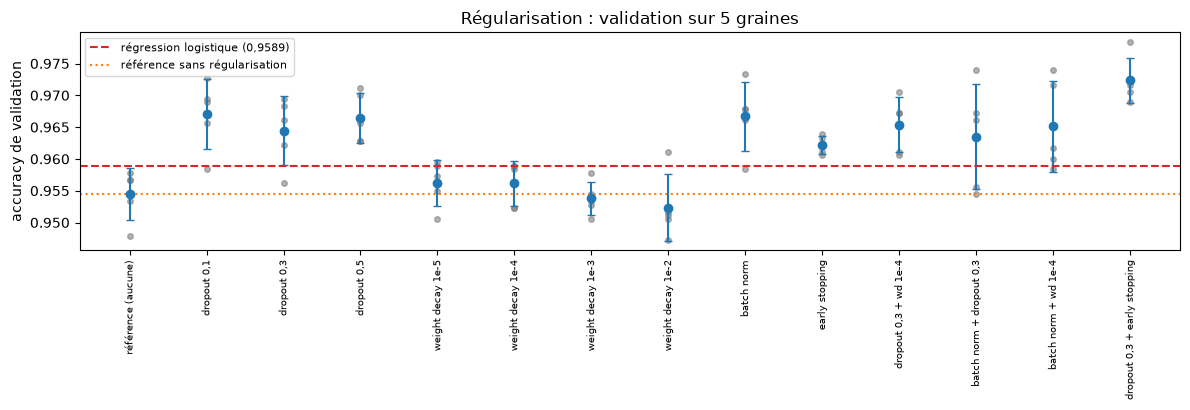

In [15]:
fig, ax = plt.subplots(figsize=(12, 4.2))
noms = list(CONFIGS_REG)
for k, nom in enumerate(noms):
    d = reg_df[reg_df["config"] == nom]
    ax.scatter([k] * len(d), d["acc_val"], color="gray", alpha=0.6, s=16)
    ax.errorbar(k, d["acc_val"].mean(), yerr=d["acc_val"].std(), fmt="o", color="C0", capsize=3)
ax.axhline(0.9589, color="C3", linestyle="--", label="régression logistique (0,9589)")
ax.axhline(reg_df[reg_df["config"] == noms[0]]["acc_val"].mean(), color="C1", linestyle=":", label="référence sans régularisation")
ax.set_xticks(range(len(noms)))
ax.set_xticklabels(noms, fontsize=7, rotation=90)
ax.set_ylabel("accuracy de validation")
ax.set_title("Régularisation : validation sur 5 graines")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Je constate que le dropout, la Batch Normalization et l'early stopping montent tous la validation autour de 0,962 à 0,972, au-dessus de la ligne orange (référence à 0,9545) et de la régression logistique (0,9589) pour la plupart. Le weight decay reste sur la ligne de la référence.

In [16]:
# Règle de 2.3 : une différence avec la référence est nette si elle dépasse 2 x le plus grand écart-type
ref = reg_df[reg_df["config"] == "référence (aucune)"]
for nom in list(CONFIGS_REG)[1:]:
    d = reg_df[reg_df["config"] == nom]
    diff = d["acc_val"].mean() - ref["acc_val"].mean()
    seuil = 2 * max(d["acc_val"].std(), ref["acc_val"].std())
    ecart_d = ((d["acc_train"] - d["acc_val"]).mean() - (ref["acc_train"] - ref["acc_val"]).mean()) * 100
    print(f"{nom:30s} validation {diff * 100:+.2f} pts (seuil {seuil * 100:.2f}, nette ? {'oui' if abs(diff) > seuil else 'non'})"
          f" | écart train-val {ecart_d:+.2f} pts")

dropout 0,1                    validation +1.25 pts (seuil 1.10, nette ? oui) | écart train-val -0.81 pts
dropout 0,3                    validation +1.00 pts (seuil 1.08, nette ? non) | écart train-val -0.74 pts
dropout 0,5                    validation +1.20 pts (seuil 0.82, nette ? oui) | écart train-val -1.54 pts
weight decay 1e-5              validation +0.18 pts (seuil 0.82, nette ? non) | écart train-val -0.09 pts
weight decay 1e-4              validation +0.17 pts (seuil 0.82, nette ? non) | écart train-val -0.05 pts
weight decay 1e-3              validation -0.07 pts (seuil 0.82, nette ? non) | écart train-val +0.10 pts
weight decay 1e-2              validation -0.21 pts (seuil 1.04, nette ? non) | écart train-val -0.48 pts
batch norm                     validation +1.22 pts (seuil 1.08, nette ? oui) | écart train-val -0.99 pts
early stopping                 validation +0.78 pts (seuil 0.82, nette ? non) | écart train-val -1.22 pts
dropout 0,3 + wd 1e-4          validation +1.0

Je remarque que 5 comparaisons sur 13 sont nettes selon ma règle de 2.3 : dropout 0,1, dropout 0,5, Batch Normalization, dropout 0,3 + weight decay et dropout 0,3 + early stopping, avec +1,1 à +1,8 point. Les autres (dropout 0,3 seul, early stopping seul, weight decay) sont des « non nettes », mais celles du dropout 0,3 et de l'early stopping sont tout près du seuil (+1,00 pour 1,08 ; +0,78 pour 0,82). Le **sens** est cohérent : toutes les configurations avec dropout, Batch Normalization ou early stopping montent de 0,8 à 1,8 point et réduisent l'écart train - validation. Comme je fais 13 comparaisons, quelques « nettes » peuvent venir du hasard ; c'est la cohérence d'ensemble qui me rassure.

Le **weight decay** ne change rien (de -0,2 à +0,2 point, écart train - validation inchangé) : la pénalité n'agit pas à ces valeurs, et à 1e-2 elle commence à gêner l'entraînement (train 0,9879).

### 4.2.2 Effet sur la stabilité

Je mesure la stabilité de deux façons : l'écart-type de l'accuracy de validation entre les 5 graines (déjà dans le tableau) et la fluctuation d'une époque à l'autre en fin d'entraînement (écart-type de l'accuracy de validation sur les 10 dernières époques, moyenné sur les graines). Plus ces valeurs sont petites, plus l'entraînement est stable.

In [17]:
stab = reg_df.groupby("config", sort=False).agg(ecart_type_graines=("acc_val", "std"),
                                                fluctuation_epoques=("fluct_val", "mean")) * 100
stab.columns = ["écart-type entre graines (pts)", "fluctuation entre époques (pts)"]
stab.round(2)

,écart-type entre graines (pts),fluctuation entre époques (pts)
config,,
référence (aucune),0.41,0.37
"dropout 0,1",0.55,0.45
"dropout 0,3",0.54,0.44
"dropout 0,5",0.39,0.37
weight decay 1e-5,0.36,0.37
weight decay 1e-4,0.36,0.36
weight decay 1e-3,0.26,0.45
weight decay 1e-2,0.52,0.66
batch norm,0.54,0.80


Je constate que la **stabilité entre graines** s'améliore peu : l'écart-type reste entre 0,3 et 0,8 point pour presque tout. Les combinaisons avec Batch Normalization sont même plus instables entre graines (0,71 à 0,83 point, contre 0,41 pour la référence). Seul l'early stopping seul est très stable (0,14 point), mais c'est en partie parce qu'on garde la meilleure époque.

La **fluctuation d'une époque à l'autre** augmente avec Batch Normalization (0,80 contre 0,37) et avec un weight decay fort (0,66). Je ne compare pas celle de l'early stopping aux autres : elle est calculée sur les 10 époques avant l'arrêt, où le réseau apprend encore, donc elle n'est pas comparable. La Batch Normalization donne de meilleurs scores mais un entraînement plus « nerveux » d'une époque à l'autre, et elle coûte plus de temps (3,3 s contre 2,0 s).

### 4.2.3 Configurations retenues pour la suite

Je retiens ces 3 configurations pour la suite, choisies sur la **moyenne de validation** et avec des mécanismes différents :

| Rang | Configuration | Validation (acc. ± écart-type) | F1 macro | Écart train - val |
|---|---|---|---|---|
| 1 | dropout 0,3 + early stopping | 0,9723 ± 0,0036 | 0,9703 | 1,60 pt |
| 2 | dropout 0,1 | 0,9670 ± 0,0055 | 0,9648 | 3,23 pts |
| 3 | batch norm | 0,9667 ± 0,0054 | 0,9648 | 3,05 pts |

Je précise trois points d'honnêteté :
- **Les rangs 2 et 3 ne sont pas séparables** de dropout 0,5 (0,9665) ni des combinaisons (0,9635 à 0,9654) : leurs écarts sont du niveau du bruit des graines (0,4 à 0,8 point). J'ai pris la meilleure moyenne de chaque famille, pas une « vraie » meilleure.
- Le rang 1 a un score de validation un peu **optimiste** : l'early stopping choisit l'époque avec la validation elle-même. Son avantage sur le dropout seul (+0,5 point) est sous le seuil de 2 écarts-types, donc je ne peux pas dire qu'il est meilleur.
- Le weight decay n'a rien apporté ; je ne le retiens pas.

Je garde aussi, comme références à comparer en 5.2, la régression logistique de la V1 et le réseau à une couche de la V1. Ces 3 configurations seront réentraînées avec le même réglage (3 couches ReLU, 128 neurones, Adam 3e-4) puis évaluées une seule fois sur le test.

In [18]:

# Configurations retenues pour la suite (Partie 5), réentraînables avec fit_reg(**params)
RETENUES = {
    "dropout 0,3 + early stopping": dict(dropout=0.3, early=True),
    "dropout 0,1": dict(dropout=0.1),
    "batch norm": dict(bn=True),
}
print(list(RETENUES))


['dropout 0,3 + early stopping', 'dropout 0,1', 'batch norm']


# Partie 5 : Visualisation et analyse des performances

> **Ce qui est demandé dans cette partie :**
> **5.1** Tracer l'évolution de la loss et de l'accuracy (ou du F1-score), sur l'entraînement et la validation, au cours des époques, pour suivre la convergence et détecter un surapprentissage ou un sous-apprentissage.
> **5.2** Évaluer une seule fois sur le test les 2 ou 3 configurations retenues et la référence de la Partie 1, comparer aux scores de validation, calculer et visualiser la matrice de confusion, et discuter les classes difficiles (la confusion est-elle plausible du point de vue des capteurs ?).

## 5.1 Courbes d'apprentissage

Je trace, pour le réseau de référence (sans régularisation) et pour les 3 configurations retenues en 4.2.3, la perte, l'accuracy (entraînement et validation) et le F1 macro de validation au fil des époques. Je ne réentraîne rien : j'utilise les historiques enregistrés en 4.1.3. Chaque courbe est la **moyenne sur les 5 graines**, avec une bande de ± 1 écart-type. Pour l'early stopping, les graines n'ont pas la même durée : je moyenne sur les graines encore actives à chaque époque, et la ligne verticale indique l'époque retenue (moyenne).

/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


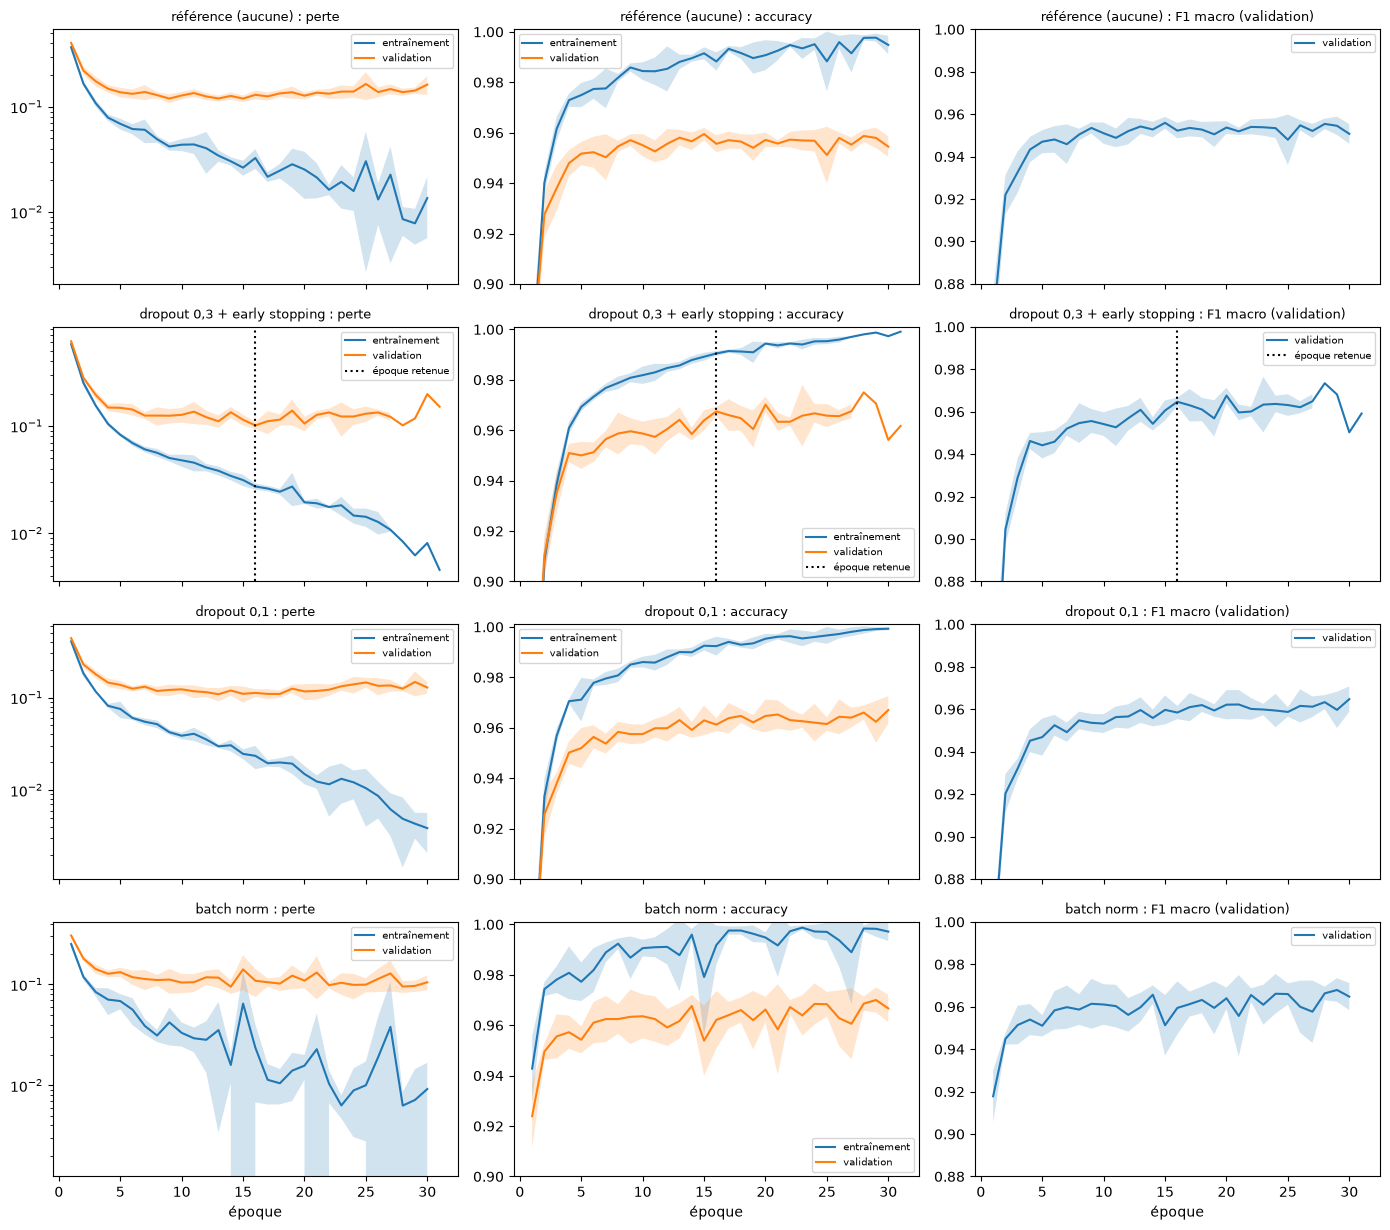

In [19]:
def courbe_moy(nom, cle):
    # Moyenne et écart-type sur les graines, époque par époque (les graines plus courtes sont ignorées après leur arrêt)
    h = [hist_reg[(nom, g)][cle] for g in SEEDS]
    n = max(len(x) for x in h)
    mat = np.full((len(h), n), np.nan)
    for k, x in enumerate(h):
        mat[k, :len(x)] = x
    return np.nanmean(mat, axis=0), np.nanstd(mat, axis=0, ddof=1)


a_tracer = ["référence (aucune)"] + list(RETENUES)
fig, axes = plt.subplots(len(a_tracer), 3, figsize=(14, 3.1 * len(a_tracer)), sharex="col")
for r, nom in enumerate(a_tracer):
    ep_ret = reg_df[reg_df["config"] == nom]["epoque"].mean()
    for c, (titre, paires) in enumerate([
            ("perte", [("train_loss", "entraînement"), ("val_loss", "validation")]),
            ("accuracy", [("train_acc", "entraînement"), ("val_acc", "validation")]),
            ("F1 macro (validation)", [("val_f1", "validation")])]):
        ax = axes[r, c]
        for cle, lab in paires:
            m, s = courbe_moy(nom, cle)
            x = np.arange(1, len(m) + 1)
            ax.plot(x, m, label=lab)
            ax.fill_between(x, m - s, m + s, alpha=0.2)
        if "early" in nom:
            ax.axvline(ep_ret, color="k", linestyle=":", label="époque retenue")
        ax.set_title(f"{nom} : {titre}", fontsize=9)
        if titre == "perte":
            ax.set_yscale("log")
        if titre == "accuracy":
            ax.set_ylim(0.9, 1.001)
        if titre.startswith("F1"):
            ax.set_ylim(0.88, 1.0)
        ax.legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel("époque")
plt.tight_layout()
plt.show()

Pour mettre des chiffres sur ce que je vois : je calcule pour chaque configuration l'époque où la perte de validation (moyenne sur les graines) est minimale, sa valeur à ce moment, et sa valeur à la dernière époque. Si la perte de validation remonte après son minimum, c'est le signe du surapprentissage.

In [20]:
lignes = []
for nom in a_tracer:
    mv, _ = courbe_moy(nom, "val_loss")
    mt, _ = courbe_moy(nom, "train_loss")
    macc, _ = courbe_moy(nom, "val_acc")
    k = int(np.argmin(mv))
    lignes.append({"configuration": nom, "époque du min. de perte val.": k + 1,
                   "perte val. minimale": round(mv[k], 3), "perte val. finale": round(mv[-1], 3),
                   "perte train finale": round(mt[-1], 4),
                   "époque du max. d'accuracy val.": int(np.argmax(macc)) + 1,
                   "accuracy val. max": round(macc.max(), 4), "accuracy val. finale": round(macc[-1], 4)})
pd.DataFrame(lignes).set_index("configuration")

/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


,époque du min. de perte val.,perte val. minimale,perte val. finale,perte train finale,époque du max. d'accuracy val.,accuracy val. max,accuracy val. finale
configuration,,,,,,,
référence (aucune),15,0.119,0.162,0.0135,15,0.9595,0.9545
"dropout 0,3 + early stopping",16,0.101,0.151,0.0046,28,0.9750,0.9617
"dropout 0,1",13,0.109,0.128,0.0039,30,0.9670,0.9670
batch norm,14,0.095,0.105,0.0092,29,0.9700,0.9667


### 5.1.1 Observations

**Surapprentissage (référence sans régularisation).** Je remarque que la perte d'entraînement continue de baisser jusqu'à l'époque 30 (0,0135) alors que la perte de validation arrête de baisser vers l'époque 15 (minimum 0,119) puis remonte (0,162 à la fin). L'accuracy d'entraînement monte vers 99,5 % pendant que celle de validation reste bloquée autour de 95,5 % à 96 % : l'écart se creuse, c'est le surapprentissage. Je ne vois pas de sous-apprentissage : l'entraînement dépasse 98 % dès l'époque 8.

**Avec le dropout 0,1.** La perte de validation a son minimum au même endroit (époque 13), mais elle remonte moins (0,109 puis 0,128). Surtout, l'accuracy de validation continue de monter doucement jusqu'à l'époque 30 (0,967) au lieu de stagner. Le dropout n'empêche pas le surapprentissage de la perte, il le ralentit.

**Avec la Batch Normalization.** La perte de validation est la plus basse et la plus plate (0,095 au minimum, 0,105 à la fin). Par contre la courbe d'entraînement est très irrégulière : des pics aux époques 14, 21 et 27, avec de grandes bandes d'incertitude. Cela correspond à ce que je voyais en 4.2.2 (fluctuation plus forte avec Batch Normalization).

**Avec l'early stopping (dropout 0,3).** Les 3 courbes s'arrêtent en moyenne à l'époque 16 (ligne pointillée), proche du minimum de la perte de validation (époque 16). Attention à la lecture : après l'époque 16, la courbe ne représente plus que 1 ou 2 graines qui ont continué, donc le bruit et le saut à 0,975 vers l'époque 28 ne sont pas représentatifs.

**Un point que je n'attendais pas.** Pour les trois configurations régularisées, la perte de validation remonte après l'époque 13 à 16 alors que l'accuracy de validation, elle, ne baisse pas. Je l'interprète ainsi : le réseau devient trop sûr de lui sur ses erreurs (la perte punit fort une mauvaise réponse très confiante), sans faire plus d'erreurs. Cela explique aussi pourquoi arrêter vers l'époque 15 coûte peu en accuracy.

**Convergence.** Dans tous les cas, l'essentiel de l'apprentissage est fait en 5 à 10 époques ; les 20 suivantes n'apportent que de petits gains de validation, voire rien.